# **FINAL PROJECT - Vannie Nguyen**

# **Predicting Cost-Related Delays in Medical Care Using MEPS 2023**

## **I. Data Selection**

**Dataset**: 2023 Medical Expenditure Panel Survey (MEPS) Full-Year Consolidated Data File (HC-251)

**Source**: Agency for HealthcareResearch and Quality (AHRQ), Medical Expenditure Panel Survey (MEPS)

**Source URL**: https://meps.ahrq.gov/mepsweb/data_stats/download_data_files_detail.jsp?cboPufNumber=HC-251

**Note for downloading the dataset**: The raw dataset is not included in this repository because of its file size. Download the data as 'MEPS2023'
1. Visit the official MEPS HC-251 download page:
   https://meps.ahrq.gov/mepsweb/data_stats/download_data_files_detail.jsp?cboPufNumber=HC-251

2. Under the **Data File, XLSX format** option, download the **ZIP**
   file.

3. Extract/unzip the downloaded file.

4. Rename the extracted Excel file to:
   `MEPS2023.xlsx`

5. Upload `MEPS2023.xlsx` when prompted by the Google Colab notebook.
The notebook expects the dataset to be named `MEPS2023.xlsx`.

Please allow approximately 10 minutes for the dataset to fully load in Google Colab. Loading time may vary depending on your internet connection and Colab's available resources.

---
The dataset selected for this project is the 2023 Medical Expenditure Panel Survey (MEPS) Full-Year Consolidated Data File (HC-251) from the Agency for Healthcare Research and Quality (AHRQ). MEPS is a nationally representative survey of the U.S. civilian noninstitutionalized population and contains information on healthcare access, utilization, health insurance, health stauts, demographics, income, and healthcare expenditures. The 2023 Full-Year Consolidated File contains data from 2023 and includes respondents from MEPS Panels 27 and 28.

This dataset was selected because it aligns closely with my academic and professional interests in healthcare access, health disparities, and health data. Satisfying the required criteria, this dataset provides an appropriate binary outcome for examining whether demographic, socioeconomic, and health-related characteristics can be used to predict delayed medical care.

The dataset satisfies the required criteria, including:
- *Binary classification*: The target variable can be recorded into a binary outcome where respondents who reported delaying medical care because of cost are coded as 1 and those who did not are coded as 0.

- *Minimum of 200 observations*: The detaset contains 18,919 observations, which is substantially greater than the required minimum of 300 observations.

- *Minimum of 10 predictor variables*: The MEPS Full-Year Consolidated File contains 1,374 variables in the version used for this project, providing substantially more than the required minimum of 10 potential predictor variables. Candidate predictors for this project include health insurance coverage, income/poverty category, age, sex, health status, and potentially health-related characteristics.

- *Alignment with academic interests*: MEPS provides data related to healthcare access and utilization, which aligns with my interests in public health, healthcare data science, and understanding factors associated with barriers to healthcare.





## **II. Dataset Exploration**

***Dataset import and structure***

The 2023 Medical Expenditure Panel SUrvey (MEPS) Full-Year Consolidated dataset was imported into Google Colab using pands. The Excel file was loaded into a DataFrame for analysis. We examined the dataset's dimensions, previewed the first 10 rows, and reviewed its structure using df.shape, df.head(10), and df.info(). These steps helped me understand the size of the dataset, inspect the available variables, identify their data types, and check the number of non-missing observations before proceeding with the analysis.

---

***Target variable identification***

The target variable for this project was DLAYCA42, which indicates whether a respondent delayed medical care because of cost. We first examined its frequency distribution to review the available response codes and identify valid responses. Only responses coded as 1 (Yes) and 2 (No) were retained for the target distribution analysis because other codes did not represent a valid Yes/No response. We then created a separate subset containing valid target responses and recoded the target into a binary outcome during the later modeling preparation stage, with 1 representing delayed care and 0 representing no delay.

An additional automated class-imbalance check was implemented to calculate the percentage of each valid target class and flag cases where the minority class represented less than 20% of valid responses. This was important because a substantial difference between the number of respondents who delayed care and those who did not could affect how machine learning models should be evaluated. The check helps identify when accuracy alone may be misleading and when additional metrics, such as precision, recall, F1-score, and ROC-AUC, should be considered.

---

***Predictor variables***

We explored the selected predictors to understand their coding and distributions. These included insurance coverage (INSCOV23), poverty category (POVCAT23), age (AGE23X), sex (SEX), race and ethnicity (RACETHX), years of education (EDUCYR), employment status (EMPST53H), marital status (MARRY23X), perceived physical health (RTHLTH53), perceived mental health (MNHLTH53), and diabetes diagnosis (DIABDX_M18). Frequency and percentage summaries were generated for categorical variables, while descriptive statistics such as the mean, median, standard deviation, minimum, and maximum were examined for age. Age was also reviewed among adults to understand the distribution of the population relevant to the modeling analysis.

---

***Descriptive statistics and class imbalance***

Descriptive statistics were used to summarize the distribution of the target variable and selected predictors. A reusable function, summarize_var(), was created to calculate frequencies and percentages for categorical variables. This reduced repetitive code and made it easier to examine multiple variables consistently.

An additional automated class-imbalance check was implemented to calculate the percentage of each valid target class and flag cases where the minority class represented less than 20% of valid responses. This was important because a substantial difference between the number of respondents who delayed care and those who did not could affect how machine learning models should be evaluated. The check helps identify when accuracy alone may be misleading and when additional metrics, such as precision, recall, F1-score, and ROC-AUC, should be considered.

### **2.1 Dataset Import and Structure**

In [1]:
# import libraries
import pandas as pd
from google.colab import files

# Upload the MEPS 2023 dataset
uploaded = files.upload()

# Load the MEPS 2023 dataset into a pandas DataFrame
df = pd.read_excel("MEPS2023.xlsx")

# file_path = "/content/drive/MyDrive/Colab Notebooks/HSE751/MEPS2023.xlsx"
# df = pd.read_excel(file_path)

Saving MEPS2023.xlsx to MEPS2023.xlsx


In [2]:
# checking # of rows and columns in the dataset
df.shape

(18919, 1374)

In [3]:
# preview first 10 rows of the dataset
df.head(10)

,DUID,PID,DUPERSID,PANEL,DATAYEAR,FAMID31,FAMID42,FAMID53,FAMID23,FAMIDYR,...,RXWCP23,RXOSR23,RXPTR23,RXOTH23,PERWT23F,FAMWT23F,FAMWT23C,SAQWT23F,VARSTR,VARPSU
0,2790002,101,2790002101,27,2023,A,A,A,A,A,...,0,0,82,0,11664.426815,11158.817826,11158.817826,13221.315673,2019,1
1,2790002,102,2790002102,27,2023,A,A,A,A,A,...,0,0,0,0,32212.113596,11158.817826,11158.817826,0.000000,2019,1
2,2790004,101,2790004101,27,2023,A,A,A,A,A,...,0,0,0,0,21944.142826,28540.745942,28540.745942,29999.277476,2084,1
3,2790006,101,2790006101,27,2023,A,A,A,A,A,...,0,0,0,0,10328.009530,10821.040689,10821.040689,11144.513916,2113,1
4,2790006,102,2790006102,27,2023,A,A,A,A,A,...,0,0,0,0,17430.521357,10821.040689,10821.040689,0.000000,2113,1
5,2790007,101,2790007101,27,2023,A,A,A,A,A,...,0,0,0,0,20123.370293,24659.806620,24659.806620,80674.378176,2085,3
6,2790011,101,2790011101,27,2023,A,A,A,A,A,...,0,0,0,0,13467.394415,12978.856984,12978.856984,12884.246699,2029,3
7,2790011,102,2790011102,27,2023,A,A,A,A,A,...,0,0,28,0,10754.599229,12978.856984,12978.856984,10855.226656,2029,3
8,2790012,101,2790012101,27,2023,A,A,A,A,A,...,0,0,11842,0,16830.149494,17072.453528,17072.453528,33671.560705,2055,2
9,2790012,102,2790012102,27,2023,A,A,A,A,A,...,0,0,10,0,28343.219605,17072.453528,17072.453528,53013.904136,2055,2


In [4]:
# review the variables, data types, and non-missing observations
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18919 entries, 0 to 18918
Columns: 1374 entries, DUID to VARPSU
dtypes: float64(16), int64(1347), object(11)
memory usage: 198.3+ MB


***Enhancement 1 - Reusable descriptive summary function***

Repeated frequency and percentage calculations were combined into a reusable function that summarizes categorical variables. This reduces duplicated code, improves notebook organization, and allows additional variables to be analyzed by simple adding them to the variable list.

In [5]:
# create a reusable function for categorical frequency and percentage summaries
def summarize_var(df, variables):
    """Display frequency and percentage distributions for categorical variables."""

    for var in variables:
        summary = pd.DataFrame({
            "Count": df[var].value_counts(dropna=False).sort_index(),
            "Percent": (
                df[var]
                .value_counts(normalize=True, dropna=False)
                .sort_index() * 100
            )
        })

        print(f"\n--- {var} ---")
        print(summary.round(2))

### **2.2 Target variable:** **DLAYCA42**

The target variable for this classification project is DLAYCA42, which measures whether a respondent delayed medical care because of cost. The variable is coded as 1 = YES an d 2 = NO. MEPS includes special codes for Don't Know (-8), Refuse (-7), and Inapplicable (-1). These special codes will be treated as missing values during data processing. Among the 18,919 observations, 1156 respondents reported delaying medical care because of cost, while 17,436 reported that they did not.

Among respondents with valid responses for DLAYCA42, 6.22% reported delaying medical care because of cost, while 93.78% reported that they did not delay medical care because of lost. This indicates that the target variable is highly imbalanced, with substantially fewer respondents in the delayed-care group. Class imbalance will therefore be considered when evaluating the classification models.

In [6]:
# check the values and frequencies of the target variable

summarize_var(df, ["DLAYCA42"])


--- DLAYCA42 ---
          Count  Percent
DLAYCA42                
-8           31     0.16
-7           48     0.25
-1          248     1.31
 1         1156     6.11
 2        17436    92.16


In [7]:
# keep only valid responses for the target variable
target_valid = df[df["DLAYCA42"].isin([1, 2])]

# count valid responses
summarize_var(target_valid, ["DLAYCA42"])


--- DLAYCA42 ---
          Count  Percent
DLAYCA42                
1          1156     6.22
2         17436    93.78


***Enhancement 2: Automatically assess class imbalance***

An automated check was added to evaluate the distribution of the target classes and flag substantial class imbalance. This was implemented because only 6.2% of valid respondents reported delaying medical care due to cost. The enhancement helps inform the model evaluation strategy by indicating that accuracy alone may not adequately describe model performance.

In [8]:
## Enhancement - automatically assess class imbalance
# Calculate the percentage of each valid target class
target_distribution = (
    target_valid["DLAYCA42"].value_counts(normalize=True) * 100
)

print("Target distribution among valid responses:")
print(target_distribution)

# Check whether the outcome has substantial class imbalance
minority_percentage = target_distribution.min()

if minority_percentage < 20:
  print("\nWarning: The target variable is substantially imbalanced.")
else:
  print("\nThe target variable does not show substantial imbalance.")

Target distribution among valid responses:
DLAYCA42
2    93.782272
1     6.217728
Name: proportion, dtype: float64



### **2.3 Descriptive stats for the main predictors:** **INSCOV23**, **POVCAT23**

Among the 18,919 respondents, 58.4% had private health insurance, 34.8% had public insurance only, and 6.9% were uninsured. Regarding family income relative to the federal poverty line, 39.0% were categorized as high income and 27.9% as middle income, while 15.2% were categorized as poor/negative, 13.1% as low income, and 4.7% as near poor.

In [9]:
# check the coding and distribution of insurance coverage
summarize_var(df, ["INSCOV23"])


--- INSCOV23 ---
          Count  Percent
INSCOV23                
1         11040    58.35
2          6581    34.79
3          1298     6.86


In [10]:
# check the coding and distribution of income/poverty categories
summarize_var(df, ["POVCAT23"])


--- POVCAT23 ---
          Count  Percent
POVCAT23                
1          2872    15.18
2           895     4.73
3          2485    13.13
4          5282    27.92
5          7385    39.03


### **2.4 Descriptive stats for other predictors:**

**AGE23X** - Respondent's age in years.
Among respondents with valid age information, the mean age was 43.5 years and the median was 44 years. Because the project focuses on adults, age will be reassessed after restricting the dataset to respondents aged 18 or older.

---

**SEX** - Respondent's sex.
The sample consisted of 47.6% males and 52.4% females. This variable is included as a demographic characteristic that may be associated with healthcare access and utilization.

---

**RACETHX** - Race and ethnicity classification.
The largest group was non-Hispanic White respondents (54.6%), followed by Hispanic respondents (22.1%), non-Hispanic Black respondents (13.3%), non-Hispanic Asian respondents (6.1%), and other/multiple race respondents (3.8%). This variable allows demographic differences in delayed medical care to be considered.

---

**EDUCYR** - Number of years of education reported when the respondent entered MEPS. Among the 17,713 respondents with valid education information, 4,497 (25.4%) reported 12 years of education, 3,020 (17.0%) reported 16 years, and 2,289 (12.9%) reported 17 or more years. There were also 1,039 (5.5%) respondents with inapplicable values, 128 (0.7%) who reported "don't know," and 39 (0.2%) who refused to answer. These special codes will be treated as missing during preprocessing.

---

**EMPST53H** - Employment status from the latest MEPS round. Among the full sample, 8,726 (46.1%) respondents were employed, 6,845 (36.2%) were not employed, and 50 (0.3%) reported having a job to return to. There were 3,298 (17.4%) inapplicable responses. Employment status was included because employment may be related to income and access to health insurance.

---

**MARRY23X** - Marital status as of Dec 31, 2023. 7,553 (39.9%) respondents were married, 4,611 (24.4%) had never been married, 1,951 (10.3%) were divorced, 1,299 (6.9%) were widowed, and 344 (1.8%) were separated. There were 3,153 (16.7%) respondents coded as under age 16/inapplicable, along with 8 responses coded as refused or don't know. The inapplicable category will not be treated as a marital-status category in the adult analysis.

---

**RTHLTH53** - Self-reported physical health status. 6,159 (32.6%) respondents reported very good health, 5,504 (29.1%) reported good health, and 4,608 (24.4%) reported excellent health. Smaller proportions reported fair health (1,905; 10.1%) or poor health (469; 2.5%). There were 212 (1.1%) inapplicable responses, 48 (0.3%) refusals, and 14 (0.1%) don't-know responses.

---

**MNHLTH53** - Self-reported mental health status. 5,864 (31.0%) respondents reported very good mental health, 5,419 (28.6%) reported good mental health, and 5,416 (28.6%) reported excellent mental health. 1,603 (8.5%) reported fair mental health and 342 (1.8%) reported poor mental health. There were 212 (1.1%) inapplicable responses, 47 (0.2%) refusals, and 16 (0.1%) don't-know responses.

---

**DIABDX_M18** - Whether the respondent reported being diagnozed with diabetes. Among the full sample, 2,154 (11.4%) respondents reported having diabetes, while 16,649 (88.0%) reported that they did not. There were 82 (0.4%) inapplicable responses, 16 (0.1%) refusals, and 18 (0.1%) don't-know responses. Diabetes was included as a health characteristic that may help predict differences in delayed medical care.

In [11]:
# descriptive statistics for age
df["AGE23X"].describe()

,AGE23X
count,18919.000000
mean,43.191712
std,24.097835
min,-1.000000
25%,22.000000
50%,44.000000
75%,64.000000
max,85.000000


In [12]:
# descriptive statistics for valid age values
age_valid = df.loc[df["AGE23X"] >= 0, "AGE23X"]

age_valid.describe()

,AGE23X
count,18771.000000
mean,43.540142
std,23.869741
min,0.000000
25%,23.000000
50%,44.000000
75%,64.000000
max,85.000000


In [13]:
# restrict the dataset to adults aged 18 years and older
adult_df = df[df["AGE23X"] >= 18].copy()

print(f"Adult observations: {len(adult_df):,}")

Adult observations: 15,123


In [14]:
# Review age distribution among adults
adult_df["AGE23X"].describe()

,AGE23X
count,15123.000000
mean,51.835086
std,18.629300
min,18.000000
25%,36.000000
50%,53.000000
75%,67.000000
max,85.000000


In [15]:
# frequency distribution for selected categorical predictors

categorical_vars = [
    "SEX",
    "RACETHX",
    "EDUCYR",
    "EMPST53H",
    "MARRY23X",
    "RTHLTH53",
    "MNHLTH53",
    "DIABDX_M18"
]

summarize_var(df, categorical_vars)


--- SEX ---
     Count  Percent
SEX                
1     9013    47.64
2     9906    52.36

--- RACETHX ---
         Count  Percent
RACETHX                
1         4188    22.14
2        10338    54.64
3         2520    13.32
4         1150     6.08
5          723     3.82

--- EDUCYR ---
        Count  Percent
EDUCYR                
-8        128     0.68
-7         39     0.21
-1       1039     5.49
 0        487     2.57
 1        291     1.54
 2        267     1.41
 3        307     1.62
 4        282     1.49
 5        269     1.42
 6        383     2.02
 7        319     1.69
 8        455     2.40
 9        504     2.66
 10       508     2.69
 11       634     3.35
 12      4497    23.77
 13       877     4.64
 14      1861     9.84
 15       463     2.45
 16      3020    15.96
 17      2289    12.10

--- EMPST53H ---
          Count  Percent
EMPST53H                
-1         3298    17.43
 1         8726    46.12
 2           50     0.26
 34        6845    36.18

--- MARR

## **III. Data Quality Assessment**

***Data quality checks***

We examined the target variable and selected predictors for missing values and improperly coded observations. The MEPS dataset uses negative values to represent special responses, including inapplicable, refused, and don't know, rather than standard missing values.

For the target variable DLAYCA42, 327 observations contained special codes and will be excluded from the classification analysis, leaving 18,592 valid responses. We also checked the selected predictors for special-coded values to identify observations that may require cleaning before modeling.

---

***Anticipated preprocessing***

The analysis will be restricted to adults aged 18 years and older with valid responses for the target variable. We will recode applicable MEPS special codes as missing values rather than treating them as meaningful numeric or categorical values. We will then handle missing predictor values through the preprocessing pipeline.

Categorical predictors will be encoded for machine learning, while age and years of education will be treated as numeric variables. Numeric variables will be imputed and standardized, while missing categorical values will be imputed using the most frequent category. These preprocessing steps will be fitted using the training data to reduce data leakage.

---

***Potential challenges***

A major challenge is class imbalance. Only 6.2% of respondents with valid target responses reported delaying medical care because of cost. Because a model could achieve high accuracy by mostly predicting that respondents did not delay care, accuracy alone would not provide a complete picture of model performance. We will also evaluate ROC-AUC, precision, recall, F1-score, and confusion matrices.

Another consideration is that MEPS uses a complex survey design with sampling weights, strata, and primary sampling units. The standard machine learning models in this project may not fully account for that design, which limits how confidently we can generalize the results to the U.S. population. We will acknowledge this limitation when interpreting the findings.


In [16]:
# combine all candidate predictors for the data quality check
predictors = [
    "INSCOV23",
    "POVCAT23",
    "AGE23X",
    "SEX",
    "RACETHX",
    "EDUCYR",
    "EMPST53H",
    "MARRY23X",
    "RTHLTH53",
    "MNHLTH53",
    "DIABDX_M18"
]

# MEPS uses negative values for special responses
special_codes = [-1, -7, -8]

# check for special-coded observations across selected predictors
print("Special-coded observations by variable:")

for var in predictors:
    count = df[var].isin(special_codes).sum()
    print(f"{var}: {count} special-coded observations")

Special-coded observations by variable:
INSCOV23: 0 special-coded observations
POVCAT23: 0 special-coded observations
AGE23X: 148 special-coded observations
SEX: 0 special-coded observations
RACETHX: 0 special-coded observations
EDUCYR: 1206 special-coded observations
EMPST53H: 3298 special-coded observations
MARRY23X: 8 special-coded observations
RTHLTH53: 274 special-coded observations
MNHLTH53: 275 special-coded observations
DIABDX_M18: 116 special-coded observations


## **IV. Exploratory Visualizations**

***Delayed Medical Care by Insurance Status***

We created a bar chart to compare the percentage of respondents who delayed medical care because of cost across three insurance groups: any private insurance, public insurance only, and uninsured. We excluded respondents with invalid responses for DLAYCA42 or INSCOV23 before calculating the percentages within each insurance group.

The percentage of respondents who reported delaying medical care because of cost varied by insurance coverage. Among respondents with private insurance, 6.0% reported delaying medical care, compared with 4.6% of respondents with public insurance only. The highest percentage was observed among uninsured respondents, with 15.9% reporting delayed medical care due to cost. This difference suggests that insurance coverage may be an important predictor of delayed medical care and will be further examined in the classification models.

To note, the chart shows an association rather than a causal relationship, and other factors, such as income and age, may also contribute to differences in access to care.

----

***Age Distribution by Delayed-Care Status***

We created a violin plot to examine the distribution of age among adults who delayed medical care because of cost and those who did not. We restricted this analysis to respondents aged 18 years and older with valid responses for DLAYCA42. We also calculated the mean and median age for each group to help interpret the visualization.

Among adults who delayed medical care because of cost, the mean age was 46.5 years and the median age was 45 years. Among adults who did not delay medical care, the mean age was 52.3 years and the median age was 54 years. The violin plot shows that adults who delayed care tended to be younger than those who did not delay care. This difference suggests that age may be an important predictor of delayed medical care. This pattern suggests that age may be a useful predictor in our classification models, although the visualization alone does not establish why the groups differ.

### **4.1 Delayed Medical Care by Insurance Status**

In [17]:
# keep respondents with valid delayed-care and insurance information
viz1_df = df[
    df["DLAYCA42"].isin([1, 2]) &
    df["INSCOV23"].isin([1, 2, 3])
].copy()

In [18]:
# calculate percentage of who delayed medical care within each insurance group

ins_delay=(
    viz1_df.groupby("INSCOV23")["DLAYCA42"]
    .apply(lambda x: (x == 1).mean() * 100)
    .reset_index(name="percent_delayed")
)

ins_delay

,INSCOV23,percent_delayed
0,1,6.035590
1,2,4.642136
2,3,15.932746


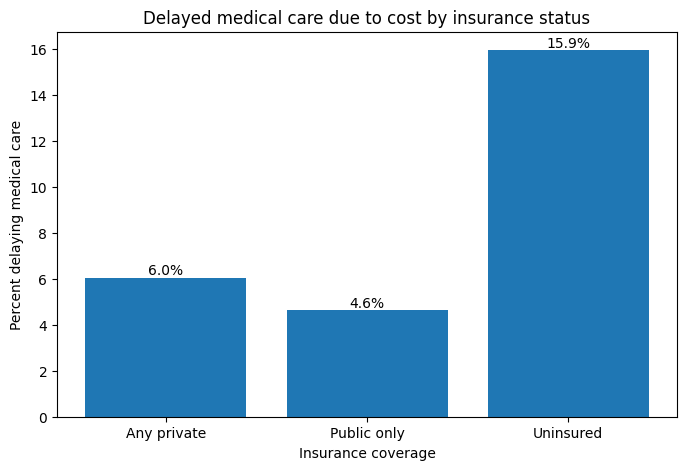

In [19]:
# bar chart for delayed care by insurance status
import matplotlib.pyplot as plt

# add readable insurance category labels
ins_delay["insurance"] = ins_delay["INSCOV23"].map({
    1: "Any private",
    2: "Public only",
    3: "Uninsured"
})

# create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ins_delay["insurance"],
    ins_delay["percent_delayed"]
)

plt.xlabel("Insurance coverage")
plt.ylabel("Percent delaying medical care")
plt.title("Delayed medical care due to cost by insurance status")

# Add percentage values above each bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom"
    )


plt.show()

### **4.2 Age Distribution by Delayed-Care Status**

In [20]:
# keep respondents age 18 or older
adult_df = df[df["AGE23X"] >= 18].copy()

# keep respondents with valid age and delayed-care responses
viz2_df = adult_df[
    adult_df["DLAYCA42"].isin([1, 2])
].copy()

# create readable labels for delayed-care status
viz2_df["delay_status"] = viz2_df["DLAYCA42"].map({
    1: "Delayed care",
    2: "Did not delay"
})

In [21]:
# calculate median age for each delayed-care group
age_summary = (
    viz2_df.groupby("delay_status")["AGE23X"]
    .agg(["count", "mean", "median"])
)

age_summary

,count,mean,median
delay_status,,,
Delayed care,1088,46.520221,45.0
Did not delay,13912,52.323821,54.0


In [22]:
# calculate age summary statistics for each group
age_summary = (
    viz2_df.groupby("delay_status")["AGE23X"]
    .agg(["count", "mean", "median"])
)

age_summary

,count,mean,median
delay_status,,,
Delayed care,1088,46.520221,45.0
Did not delay,13912,52.323821,54.0


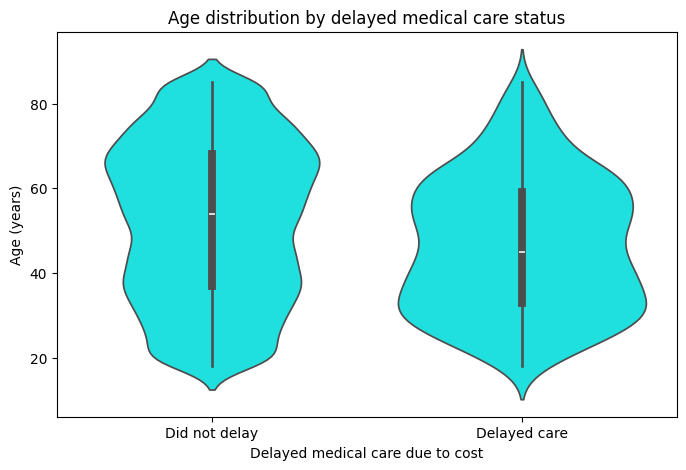

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt

# create violin plot of age by delayed-care status
plt.figure(figsize=(8, 5))

sns.violinplot(
    data=viz2_df,
    x="delay_status",
    y="AGE23X",
    color="cyan",
    inner="box"
)

plt.xlabel("Delayed medical care due to cost")
plt.ylabel("Age (years)")
plt.title("Age distribution by delayed medical care status")

plt.show()

## **V. Inferential Statistical Analysis**

Inferential statistical tests were conducted to examine whether selected predictors were statistically associated with delayed medical care because of cost. Chi-square tests were used for categorical variables, an independent-samples t-test was used to compare mean age between delayed-care groups, and one-way ANOVA was used to compare mean age across insurance coverage groups. These analyses are intended to identify statiscally significant relationships that can inform the subsequent classification models. Statistical significant was assessed at α = 0.05.

***Summary***

Four inferential statistical tests were conducted to examine the relationships between delayed medical care due to cost, insurance coverage, poverty category, and age. The chi-square test found a statistically significant association between insurance coverage and delayed medical care ($\chi^2(2) = 230.20),\ p < .001$). Uninsured respondents had the highest percentage of delayed care at 15.9%, compared with 6.0% among respondents with any private insurance and 4.6% among those with public insurance only. A second chi-square test also found a significant association between poverty category and delayed care ($\chi^2(4) = 35.946,\ p < .001$). Delayed-care percentages varied across income groups, ranging from 4.9% among respondents in the high-income category to 7.5% among those in the low-income category.

The Welch independent-samples t-test found a statistically significant difference in mean age between adults who delayed care and those who did not ($t = -11.437,\ p < .001$). Adults who delayed care had a lower mean age (46.52 years) than those who did not delay care (52.32 years). Welch's t-test was used because it does not assume equal variances between the two groups. Finally, the one-way ANOVA found a statistically significant difference in mean age across insurance coverage groups ($F = 824.669,\ p < .001$). Adults with public insurance only had the highest mean age (59.65 years), while uninsured adults had the lowest (40.46 years).

Overall, these findings suggest that insurance coverage, poverty category, and age are relevant characteristics to examine when predicting delayed medical care due to cost. The results support including these variables in the classification models, although the statistical tests identify associations and group differences rather than causal relationships. These analyses used standard, unweighted statistical tests and did not account for MEPS's complex survey design.

***Note***

One limitation of this analysis is that MEPS uses a complex survey design, including sampling weights, strata, and primary sampling units. For this course project, standard unweighted statistical tests and machine-learning methods were used to focus on the analysis workflow and model comparison. Therefore, the results should be interpreted as findings from the analyzed sample rather than survey-design-adjusted national estimates. Future analyses could incorporate the MEPS survey design to improve the interpretation of population-level estimates.

### **5.1 Chi-Square Test: Insurance x Delayed Care**

**Educational note: What Is a Chi-Square Test of Independence?**

A chi-square test of independence is a statistical test used to examine whether two categorical variables are associated with each other. It compares the observed counts in each combination of categories with the counts we would expect if the two variables were independent.

The test evaluates two hypotheses:
- **Null hypothesis ($H_0$)**: The two categorical variables are independent, meaning there is no association between them in the population being studied.
- **Alternative hypothesis ($H_A$)**: The two categorical variables are associated with each other.

The test produces a chi-sequare statistic and a p-value. A small p-value (commonly less than 0.5) provides evidence against the null hypothesis, suggesting an association between the variables. However, statistical significance does not establish causation or indicate how large or practically important the association is.

---

**Why did we choose this test?**

We used a chi-square test of independence to examine the relationship between health insurance coverage (INSCOV23) and delayed medical care due to cost (DLAYCA42).

Both variables are categorical. Insurance status consists of three groups—any private insurance, public insurance only, and uninsured—while delayed medical care has two valid responses: yes or no. A chi-square test allows us to determine whether the proportion of respondents who delayed care differs across the three insurance groups.

This test is relevant to our research question because insurance coverage may be related to access to healthcare and the ability to afford medical services. Examining this relationship helps us understand the data before developing classification models to predict delayed medical care.

Before conducting the test, we exclude observations with invalid or special-coded responses for either variable. We also check that the expected cell counts are sufficiently large for the chi-square approximation to be appropriate. Because MEPS uses a complex survey design, this standard chi-square test should be interpreted as an unweighted analysis unless survey weights and design features are explicitly incorporated.

---

**Is insurance coverage associated with whether an adult delays medical care because of cost?**
- Null: Insurance coverage and delayed medical care due to cost have no association.
- Alternative: Insurance coverage and delayed medicare care due to cost are associated.

***Interpretation***:

The chi-square test found a statistically significant association between insurance coverage and delaying medical care due to cost ($\chi^2(2)=230.20),\ p < .001$). The p-value is below 0.05, so we reject the null hypothesis of independence. Among respondents with private insurance, 6.0% reported delaying care, compared with 4.6% of those with public insurance only and 15.9% of uninsured respondents. Uninsured respondents had the highest percentage of delayed care due to cost. These findings suggest that insurance status is associated with access to timely medical care and support including including insurance coverage as a predictor in the classification models. To note, this association does not establish causation.


In [24]:
from scipy.stats import chi2_contingency, ttest_ind, f_oneway

# Create a contingency table for insurance coverage and delayed medical care
insurance_table = pd.crosstab(
    viz1_df["INSCOV23"],
    viz1_df["DLAYCA42"]
)

insurance_table


DLAYCA42,1,2
INSCOV23,,
1,658,10244
2,299,6142
3,199,1050


In [25]:
# Perform the chi-square test
chi2, p_value, dof, expected = chi2_contingency(insurance_table)

# Print the results
print(f"Chi-square statistic: {chi2:.2f}")
print(f"P-value: {p_value:.4f}")
print(f"Degrees of freedom: {dof}")

Chi-square statistic: 230.20
P-value: 0.0000
Degrees of freedom: 2


### **5.2 Chi-Square Test: Poverty x Delayed Care**

We conducted a chi-square test of independence to examine whether poverty category (POVCAT42) was associated with delayed medical care due to cost (DLAYCA42). We chose this test because both variables are categorical. Poverty category divides respondents into five income-related groups, ranging from poor or negative income to high income, while delayed medical care has two valid response categories: yes or no.

This analysis helps us examine whether delayed medical care varies across income groups. Since affordability is a central part of our research question, understanding the relationship between poverty category and delayed care provides useful context for selecting predictors for our classification models.

---

**Is poverty category associated with whether an adult delays medical care because of cost?**

- Null: Poverty levels and delayed medical care due to cost have no association.
- Alternative: Poverty levels and delayed medicare care due to cost are associated.

***Interpretation***:

The chi-square test found a statistically significant association between poverty category and delaying medical care due to cost ($\chi^2(4)=35.946,\ p<0.001$). Therefore, we reject the null hypothesis.

When we compared the percentage of respondents who delayed care across poverty categories, the highest percentage was observed among respondents in the poor or negative-income category (7.3%), followed by the low-income group (7.5%), near-poor group (6.5%), middle-income group (6.8%), and high-income group (4.9%). Although the low-income group had a slightly higher percentage than the poor or negative-income group, the high-income group had the lowest percentage overall.

These results suggest that income-related differences may be associated with delayed medical care. However, the relationship is not strictly linear across the five categories, and statistical significance does not establish causation. Other characteristics, including insurance status and age, may also contribute to the observed differences.

In [26]:
# Create a contingency table for poverty category and delayed medical care
poverty_table = pd.crosstab(
    df.loc[
        df["DLAYCA42"].isin([1, 2]) &
        df["POVCAT23"].isin([1, 2, 3, 4, 5]),
        "POVCAT23"
    ],
    df.loc[
        df["DLAYCA42"].isin([1, 2]) &
        df["POVCAT23"].isin([1, 2, 3, 4, 5]),
        "DLAYCA42"
    ]
)

poverty_table


DLAYCA42,1,2
POVCAT23,,
1,204,2597
2,57,817
3,182,2247
4,353,4840
5,360,6935


In [27]:
# Perform chi-square test of independence
chi2_poverty, p_poverty, dof_poverty, expected_poverty = chi2_contingency(poverty_table)

print(f"Chi-square statistic: {chi2_poverty:.3f}")
print(f"P-value: {p_poverty:.4f}")
print(f"Degrees of freedom: {dof_poverty}")

Chi-square statistic: 35.946
P-value: 0.0000
Degrees of freedom: 4


### **5.3 Independent-Samples t-Test: Age x Delayed Care**

**Educational note: What Is an Independent-Samples t-Test?**

An independent-samples t-test is a statistical test used to compare the **means of a continuous variable between two independent groups.** It helps us determine whether the observed difference between the groups' averages is statistically significant or could reasonably be due to random variation in the sample.

- **Null hypothesis ($H_0$)**: The mean age is the same for people who delayed medical care due to cost and those who did not.
- **Alternative hypothesis ($H_A$)**: The mean age differs between the two groups.

A p-value below 0.05 is commonly interpreted as evidence against the null hypothesis. However, statistical significance does not necessarily mean the difference is large or practically important, and it does not establish causation.

The appropriate type of t-test depends on the research question, the type of data, and whether the observations are independent or paired.

| Type of t-test | Purpose | Main assumptions |
|---|---|---|
| **One-sample t-test** | Compares one sample mean with a reference value. | Continuous outcome, independent observations, and an approximately normal sampling distribution of the mean. |
| **Student's independent-samples t-test** | Compares the means of two independent groups. | Continuous outcome, independent observations, approximate normality within each group, and equal population variances. |
| **Welch's independent-samples t-test** | Compares the means of two independent groups without assuming equal variances. | Continuous outcome, independent observations, and approximate normality within each group or sufficiently large samples for robustness. |
| **Paired-samples t-test** | Compares two measurements from the same individuals or matched pairs. | Continuous outcome, paired measurements, independence between pairs, and approximate normality of the within-pair differences. |

**Assumptions and Considerations**

- Continuous outcome - The variable being compared should be numeric, such as age.
- Independence - Observations should be independent within and between groups, as appropriate for the test. Repeated measurements from the same person require a paired approach.
- Normality - The outcome distributions should be reasonably well behaved within each group, or the sample sizes should be sufficient for the mean comparison to be robust. Strong skewness and extreme outliers may affect results.
- Equal variances - Student’s independent-samples t-test assumes equal population variances. Welch’s test does not require this assumption and adjusts the degrees of freedom accordingly.
- Appropriate sampling design - Standard t-tests assume an appropriate independent sampling structure. Because MEPS uses a complex survey design, a standard t-test does not account for its survey weights, strata, and primary sampling units.

---

**Why did we choose this test?**

We chose Welch’s t-test because our research question compares the mean age (AGE23X) of two independent groups: adults who delayed medical care due to cost and adults who did not (DLAYCA42). Age is a continuous variable, and delayed-care status is a binary categorical variable.

Welch’s test is particularly appropriate because it does not require the two groups to have equal population variances. This makes it a practical default when comparing two group means, especially when group sizes or variances may differ.

For this analysis, we restricted the sample to adults aged 18 or older with valid responses for delayed-care status. We also note that the standard t-test does not account for MEPS's complex survey design or sampling weights.

---

**Does the mean age differ between adults who delayed medical care because of cost and those who did not?**

- Null - The mean age is equal between adults who delayed medical care due to cost and adults who did not delay care.
- Alternative - The mean age differs between adults who delayed medical care due to cost and adults who did not delay care.

***Interpretation***

The Welch independent-samples t-test found a statistically significant difference in mean age between adults who delayed medical care because of cost and those who did not ($t = -11.437,\ p < .001$). Welch's t-test was used because it does not assume equal variances between the two groups, which is useful given the substantial difference in their sample sizes. Adults who delayed care had a mean age of 46.52 years, compared with 52.32 years among those who did not delay care. This represents a mean difference of approximately 5.80 years, with the delayed-care group being younger on average. These findings suggest that age may be associated with delaying medical care due to cost and support including age as a predictor in the classification models. We reject the null hypothesis. However, this test identifies a difference in group averages and does not establish that age causes delayed care.

In [28]:
viz2_df

,DUID,PID,DUPERSID,PANEL,DATAYEAR,FAMID31,FAMID42,FAMID53,FAMID23,FAMIDYR,...,RXOSR23,RXPTR23,RXOTH23,PERWT23F,FAMWT23F,FAMWT23C,SAQWT23F,VARSTR,VARPSU,delay_status
0,2790002,101,2790002101,27,2023,A,A,A,A,A,...,0,82,0,11664.426815,11158.817826,11158.817826,13221.315673,2019,1,Did not delay
1,2790002,102,2790002102,27,2023,A,A,A,A,A,...,0,0,0,32212.113596,11158.817826,11158.817826,0.000000,2019,1,Did not delay
2,2790004,101,2790004101,27,2023,A,A,A,A,A,...,0,0,0,21944.142826,28540.745942,28540.745942,29999.277476,2084,1,Did not delay
3,2790006,101,2790006101,27,2023,A,A,A,A,A,...,0,0,0,10328.009530,10821.040689,10821.040689,11144.513916,2113,1,Did not delay
4,2790006,102,2790006102,27,2023,A,A,A,A,A,...,0,0,0,17430.521357,10821.040689,10821.040689,0.000000,2113,1,Did not delay
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18912,2819784,102,2819784102,28,2023,A,A,A,A,A,...,0,0,0,4136.424108,5126.030033,5126.030033,5596.586343,2015,1,Did not delay
18915,2819788,101,2819788101,28,2023,A,A,A,A,A,...,0,1353,0,4266.149133,3608.933864,3608.933864,4902.751776,2005,1,Did not delay
18916,2819792,101,2819792101,28,2023,A,A,A,A,A,...,0,0,0,27269.051680,26238.599825,26238.599825,0.000000,2012,3,Did not delay
18917,2819793,101,2819793101,28,2023,A,A,A,A,A,...,0,0,0,14138.195827,15780.213332,15780.213332,0.000000,2004,1,Did not delay


In [29]:
# Separate age values by delayed-care status
delayed_age = viz2_df.loc[
    viz2_df["DLAYCA42"] == 1,
    "AGE23X"
]

not_delayed_age = viz2_df.loc[
    viz2_df["DLAYCA42"] == 2,
    "AGE23X"
]

In [30]:
# Compare mean age between delayed-age groups
t_stat, p_value_age = ttest_ind(
    delayed_age,
    not_delayed_age,
    equal_var=False
)

print(f"t-statistic: {t_stat:.3f}")
print(f"P-value: {p_value_age:.4f}")


t-statistic: -11.437
P-value: 0.0000


In [31]:
# compare the mean age within each delayed-age group
age_means = viz2_df.groupby("delay_status")["AGE23X"].mean()

age_means

,AGE23X
delay_status,
Delayed care,46.520221
Did not delay,52.323821


### **5.4 One-Way ANOVA: Age x Insurance Coverage**

**Educational note: What Is a One-Way ANOVA?**

A one-way analysis of variance (ANOVA) is an inferential statistical test used to compare the means of a continuous variable across three or more independent groups. It evaluates whether the differences between group means are large relative to the variation within each group.

Although the name refers to variance, the purpose is to test whether the group means differ.

- **Null hypothesis ($H_0$)**: The mean is equal across three or more independent groups.
- **Alternative hypothesis ($H_A$)**: The mean differs between the groups.

A p-value below 0.05 provides evidence against the null hypothesis. However, a statistically significant result does not tell us which specific groups differ; additional post-hoc comparisons may be needed.

**Assumptions and Considertions**

| **Assumption** | **Explanation** |
|---|---|
| Continuous outcome | The outcome should be numeric, such as age (AGE23X) |
Independent observations | Each observation should be independent of the others, and each person should belong to one comparison group. |
Approximate normality | Age should be reasonably well behaved within each insurance group, although ANOVA can be robust to moderate departures from normality with sufficiently large samples. |
Homogeneity of variances | Standard one-way ANOVA assumes that the population variances are approximately equal across groups. This can be assessed using Levene's test and by examining group distributions. |
Appropriate sampling design | Standard ANOVA does not account for MEPS's complex survey design, including its weights, strata, and primary sampling units.

---

**Why did we choose One-Way ANOVA?**

We chose one-way ANOVA because our research question examines whether mean age differs across the three insurance coverage groups recorded in INSCOV23:

- Any private insurance
- Public insurance only
- Uninsured

Age (AGE23X) is a continuous variable, while insurance coverage is a categorical variable with three groups. One-way ANOVA allows us to compare all three group means in a single overall test rather than conducting multiple independent t-tests, which could increase the risk of false-positive findings.

For this analysis, we use respondents with valid age and insurance coverage values. We will interpret the p-value to determine whether there is evidence of a difference in mean age across the groups. If the result is statistically significant, we can use appropriate post-hoc comparisons to investigate which groups differ.

Because we are using a standard ANOVA rather than a survey-adjusted analysis, the results should be interpreted with the limitation that MEPS's complex sampling design is not accounted for. Any observed differences describe associations in our analyzed sample and do not establish causation.


---

**Does the mean age of adults differ across insurance coverage groups?**
- Null - The mean age is equal across all 3 insurance groups.
- Alternative - The mean age is NOT equal across the 3 insurance groups.

***Interpretation***

The one-way ANOVA found a statistically significant difference in mean age across the three insurance coverage groups ($F = 824.669\,\ p < .001\$). Adults with public insurance only had the highest mean age (59.65 years), followed by adults with any private insurance (49.11 years), while uninsured adults had the lowest mean age (40.46 years). These findings indicate that age varies across insurance coverage groups and suggest that age and insurance status may capture related demographic characteristics in the classification models. We reject the null hypothesis. However, the ANOVA does not identify which specific pairs of insurance groups differ significantly, and the results do not establish causation.


In [32]:
# keep adults with valid age and insurance information

anova_df = adult_df[
    adult_df["INSCOV23"].isin([1, 2, 3])
].copy()

# assign readable insurance labels
anova_df["insurance"] = anova_df["INSCOV23"].map({
    1: "Any private",
    2: "Public only",
    3: "Uninsured"
})


In [33]:
# compare age across insurance groups
anova_summary = (
    anova_df.groupby("insurance")["AGE23X"]
    .agg(["count", "mean", "median", "std"])
)

anova_summary


,count,mean,median,std
insurance,,,,
Any private,9079,49.107170,49.0,17.181081
Public only,4874,59.645876,66.0,19.460583
Uninsured,1170,40.464957,40.0,13.298027


In [34]:
# separate ages by insurance coverage
private_age = anova_df.loc[
    anova_df["INSCOV23"] == 1, "AGE23X"
]

public_age = anova_df.loc[
    anova_df["INSCOV23"] == 2, "AGE23X"
]

uninsured_age = anova_df.loc[
    anova_df["INSCOV23"] == 3, "AGE23X"
]

# perform one-way ANOVA
f_stat, p_value_anova = f_oneway(
    private_age,
    public_age,
    uninsured_age
)

print(f"F-statistic: {f_stat:.3f}")
print(f"P-value: {p_value_anova:.6f}")

# interpret the result at the 0.05 significance level
if p_value_anova < 0.05:
    print("Conclusion: Mean age differs significantly across insurance groups.")
else:
    print("Conclusion: No statistically significant difference in mean age was detected.")

F-statistic: 824.669
P-value: 0.000000
Conclusion: Mean age differs significantly across insurance groups.


## **VI. Machine Learning Model**

**Educational note: Introduction to Machine Learning**

**What is Machine Learning?**

Machine learning (ML) is a branch of data science that uses algorithms to learn patterns from data and make predictions or identify relationships. Instead of explicitly programming every decision rule, we provide the algorithm with data so it can learn patterns that may be useful for making predictions on new observations.

Machine learning can be used for tasks such as predicting health outcomes, identifiying patients who may need additional support, detecting patterns in healthcare utilization, and supporting public health decision-making.

**What are the main types of Machine Learning?**

| **Type** | **Purpose** | **Example** |
|---|---|---|
| **Supervised learning** | Learns patterns from data with known outcomes or labels | Predicting whether a person will delay medical care due to cost. |
| **Unsupervised learning**| Identifies patterns or groups in data without a predefined outcome label. | Identifying groups of patients with similar healthcare utilization patterns.|
|**Reinforcement learning**| Learns strategies by receiving feedback or rewards from actions taken in an environment. | Developing a strategy for allocating resources across changing healthcare needs.|

---

**Our Project Goal: Supervised Binary Classification**

For this project, we used supervised learning, specifically binary classification. Our dataset contains a known outcome, DLAYCA42, indicating whether a responent delayed medical care due to cost.

We recoded the outcome as:
- 1 = Delayed medical care due to cost
- 0 = Did not delay medical care due to cost

Our goal is to investigate whether insurance coverage, income, age, education, and other selected demographic and health characteristics can help predict this outcome.

The purpose is not to establish causation or claim that the model can definitively identify everyone who will delay care. Instead, we want to evaluate how well the models distinguish between people who did and did not report delaying medical care due to cost.

**MODEL 1: Logistic Regression**

Logistic regression is a supervised learning algorithm commonly used for binary classification. It estimates the probability that an observation belongs to the positive class, which, in our project, is the probability that a respondent delayed care due to cost.

The model estimates how the predictors relate to the probability of the outcome. Its results can also be interpreted through coefficients and odds ratios, although categorical encoding and other modeling choices affect how those results should be interpreted.

We chose logistic regression because it provides a useful baseline model for a binary outcome and offers a relatively interpretable way to examine how selected characteristics relate to the predicted likelihood of delayed care. We also use class weighting to help address the imbalance between respondents who delayed care and those who did not.

**MODEL 2: Random Forest**

Random forest is a supervised learning algorithm that combines predictions from many decision trees. Each tree learns patterns from the data, and the forest combines their predictions to produce an overall result.

Compared with logistic regression, random forest can capture more complex relationships and interactions among predictors without requiring us to specify those relationships in advance. However, its predictions and feature importance measures can be less straightforward to interpret.

We chose random forest because it allows us to compare a more flexible, tree-based model with logistic regression. This helps us investigate whether capturing more complex patterns improves prediction of delayed medical care.

**Why Both Models?**

We use both models because they offer different strengths:

- Logistic regression: Provides a relatively interpretable baseline and estimates outcome probabilities using a structured statistical relationship.

- Random forest: Can capture nonlinear patterns and interactions that logistic regression may not represent adequately without additional feature engineering.

Comparing the models helps us assess whether the more flexible random forest performs better than logistic regression on our dataset. Neither model is automatically superior; performance must be evaluated using appropriate metrics.

---

**Overview of the Machine Learning Workflow**

| **Step** | **Purpose** |
|---|---|
|6.1. Data cleaning and preprocessing | Handle invalid or special-coded values and prepare variables for modeling. |
|6.2 Train-Test Split|Separate the data into training and testing sets so we can evaluate performance on observations not used to fit the models.|
|6.3 Build Preprocessing Pipelines|Organize imputation, scaling, and categorical encoding into a consistent, reproducible workflow.|
|6.4 Train Logistic Regression|Fit the baseline classification model using the training data.|
|6.5 Train Random Forest|Fit the tree-based classification model using the same training data.|
|6.6 Evaluate and Compare Models|Compare accuracy, precision, recall, F1-score, and ROC-AUC to understand different aspects of model performance.|
|6.7. ROC Curve and Classification Threshold Analysis| Examine how the models distinguish between classes and how changing the probability threshold affects classification results.|
|6.8 Feature Importance and Model Interpretation| Explore which predictors contribute to the model's predictions and interpret the findings cautiously.|

Throughout this workflow, we pay particular attention to class imbalance. A model could achieve high accuracy by predicting that most respondents did not delay care, while still failing to identify people who did. Therefore, we will evaluate several metrics rather than relying on accuracy alone.

We also recognize that MEPS uses a complex survey design. Our current models do not fully account for its survey weights, strata, and primary sampling units, which limits how confidently we can generalize the results to the U.S. population.


### **6.1 Data Cleaning and Preprocessing**

A separate modeling dataset was created by restricting the analysis to adults aged 18 and older with valid responses to the target variable, DLAYCA42. Respondents with missing or invalid target responses were excluded because their delayed-care status could not be determined. The target variable was then recoded into a binary format, with 1 representing respondents who delayed medical care because of cost and 0 representing those who did not. The resulting dataset contained 15,000 observations and 12 variables, including one target variable and 11 predictors. Of these adults, 1,088 (7.25%) reported delaying care, while 13,912 (92.75%) did not. This distribution indicates class imbalance, which will be considered when evaluating model performance using precision, recall, F1-score, and ROC-AUC rather than relying on accuracy alone.

The 11 selected predictors included insurance coverage (INSCOV23), poverty category (POVCAT23), age (AGE23X), sex (SEX), race and ethnicity (RACETHX), years of education (EDUCYR), employment status (EMPST53H), marital status (MARRY23X), perceived physical health (RTHLTH53), perceived mental health (MNHLTH53), and diabetes diagnosis (DIABDX_M18). These variables were selected to examine whether insurance, socioeconomic, demographic, and health-related characteristics could help predict delayed medical care due to cost.

We also inspected the predictors for missing values and MEPS-specific special response codes. Although no conventional missing values were initially detected, several variables contained numeric codes representing responses such as “don't know,” “refused,” or “inapplicable.” These codes were converted to missing values where appropriate. Valid values were retained, including 0 for years of education and 34 for employment status. After cleaning, the dataset remained at 15,000 observations and 12 variables, with missing values in five predictors: EDUCYR (139), MARRY23X (3), RTHLTH53 (103), MNHLTH53 (107), and DIABDX_M18 (26). Rather than removing these observations, we will handle the missing predictor values through imputation within the machine learning preprocessing pipelines. This allows the models to retain as much available data as possible while ensuring that imputation is learned from the training data to reduce the risk of data leakage.

In [35]:
# select adults aged 18 or older with valid target responses
model_vars = [
    "DLAYCA42",
    "INSCOV23", "POVCAT23", "AGE23X", "SEX", "RACETHX",
    "EDUCYR", "EMPST53H", "MARRY23X", "RTHLTH53",
    "MNHLTH53", "DIABDX_M18"
]

model_df = df.loc[
    (df["AGE23X"] >= 18) &
    (df["DLAYCA42"].isin([1, 2])),
    model_vars
].copy()

# convert the target to binary:
# 1 = delayed care, 0 = did not delay care
model_df["DLAYCA42"] = model_df["DLAYCA42"].map({
    1: 1,
    2: 0
})

print("Modeling dataset shape:", model_df.shape)
print("\nTarget distribution:")
print(model_df["DLAYCA42"].value_counts())
print("\nTarget percentages:")
print((model_df["DLAYCA42"].value_counts(normalize=True) * 100).round(2))

Modeling dataset shape: (15000, 12)

Target distribution:
DLAYCA42
0    13912
1     1088
Name: count, dtype: int64

Target percentages:
DLAYCA42
0    92.75
1     7.25
Name: proportion, dtype: float64


In [36]:
# check missing values and unique values in each predictor
predictors = [
    "INSCOV23", "POVCAT23", "AGE23X", "SEX", "RACETHX",
    "EDUCYR", "EMPST53H", "MARRY23X", "RTHLTH53",
    "MNHLTH53", "DIABDX_M18"
]

for col in predictors:
    print(f"\n--- {col} ---")
    print("Missing values:", model_df[col].isna().sum())
    print("Unique values:", sorted(model_df[col].dropna().unique().tolist()))


--- INSCOV23 ---
Missing values: 0
Unique values: [1, 2, 3]

--- POVCAT23 ---
Missing values: 0
Unique values: [1, 2, 3, 4, 5]

--- AGE23X ---
Missing values: 0
Unique values: [18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85]

--- SEX ---
Missing values: 0
Unique values: [1, 2]

--- RACETHX ---
Missing values: 0
Unique values: [1, 2, 3, 4, 5]

--- EDUCYR ---
Missing values: 0
Unique values: [-8, -7, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]

--- EMPST53H ---
Missing values: 0
Unique values: [1, 2, 34]

--- MARRY23X ---
Missing values: 0
Unique values: [-7, 1, 2, 3, 4, 5]

--- RTHLTH53 ---
Missing values: 0
Unique values: [-8, -7, -1, 1, 2, 3, 4, 5]

--- MNHLTH53 ---
Missing values: 0
Unique values: [-8, -7, -1, 1, 2, 3, 4, 5]

--- DIABDX_M18 ---


In [37]:
# check the frequency of potential special codes in each predictor
potential_special_codes = {
    "EDUCYR": [-8, -7],
    "MARRY23X": [-7],
    "RTHLTH53": [-8, -7, -1],
    "MNHLTH53": [-8, -7, -1],
    "DIABDX_M18": [-8, -7]
}

for col, codes in potential_special_codes.items():
    print(f"\n--- {col} ---")
    for code in codes:
        count = (model_df[col] == code).sum()
        print(f"Code {code}: {count} ({count / len(model_df) * 100:.2f}%)")


--- EDUCYR ---
Code -8: 110 (0.73%)
Code -7: 29 (0.19%)

--- MARRY23X ---
Code -7: 3 (0.02%)

--- RTHLTH53 ---
Code -8: 8 (0.05%)
Code -7: 32 (0.21%)
Code -1: 63 (0.42%)

--- MNHLTH53 ---
Code -8: 12 (0.08%)
Code -7: 32 (0.21%)
Code -1: 63 (0.42%)

--- DIABDX_M18 ---
Code -8: 17 (0.11%)
Code -7: 9 (0.06%)


***Enhancement 3: MEPS-specific data cleaning***

We inspected predictors for MEPS special response codes and converted invalud response codes such as -7, -8, and applicable -1 values into missing values. The standard missing-value checks did not detect these numeric codes, which could otherwise be incorrectly treated as meaningful data. This step makes data cleaning more appropriate for the MEPS dataset while preserving valid values such as 0 years of education and employment category 34.

In [38]:
# Create a separate copy for cleaning
model_df_clean = model_df.copy()

# Convert confirmed MEPS special response codes to missing values
special_codes = {
    "EDUCYR": [-8, -7],
    "MARRY23X": [-7],
    "RTHLTH53": [-8, -7, -1],
    "MNHLTH53": [-8, -7, -1],
    "DIABDX_M18": [-8, -7]
}

for col, codes in special_codes.items():
    model_df_clean[col] = model_df_clean[col].replace(codes, float("nan"))

# Check the number of missing values after cleaning
print("Missing values after cleaning:")
print(model_df_clean[predictors].isna().sum())

print("\nCleaned dataset shape:", model_df_clean.shape)

Missing values after cleaning:
INSCOV23        0
POVCAT23        0
AGE23X          0
SEX             0
RACETHX         0
EDUCYR        139
EMPST53H        0
MARRY23X        3
RTHLTH53      103
MNHLTH53      107
DIABDX_M18     26
dtype: int64

Cleaned dataset shape: (15000, 12)


### **6.2 Train-Test Split**

A train-test split separates a dataset into two subsets for different purposes:
- **Training set**: Used to teach the machine learning model patterns and relationships between the predictors and the target outcome.
- **Testing set**: Used to evaluate how well the trained model predicts outcomes for observations it has not seen during training.

This separation is important because a model may perform well on the data it was trained on but perform less effectively on new observations. Evaluating the model on a separate testing set provides a more realistic assessment of its ability to generalize beyond the training data.

For our project, we use an 80/20 split, with 80% of the data for training and 20% for testing. We also use a stratified split to maintain similar proportions of delayed-care and non-delayed-care cases in both sets, which is especially important because delayed-care cases represent only about 7.25% of our sample. Setting random_state=42 makes the split reproducible, allowing us to obtain the same partition when we rerun the notebook with the same data and settings.

The testing set should remain separate from model training and model-selection decisions as much as possible so that it can provide a fairer final evaluation of model performance.

Our stratified split helps preserve the class proportions, but it does not solve class imbalance itself. That's why we also use class weighting and evaluate metrics such as recall, precision, F1-score, and ROC-AUC rather than relying on accuracy alone.

***Enhancement 4: Stratified, reproducible train-test split***

We split the 15,000 observations into 12,000 training and 3,000 testing observations using stratify=y and random_state=42. Only 7.25% of adults reported delaying care, so the outcome distribution needed to be preserved across the two sets. This step supports reproducible evaluation and helps ensure that both sets contain a similar proportion of delayed-care cases.

In [39]:

from sklearn.model_selection import train_test_split

# separate the target variable from the predictors
X = model_df_clean[predictors].copy()
y = model_df_clean["DLAYCA42"].copy()

# split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# check the size of each dataset
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

# check whether the outcome proportions are similar
print("\nTraining outcome proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nTesting outcome proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(4))


Training set shape: (12000, 11)
Testing set shape: (3000, 11)

Training outcome proportions:
DLAYCA42
0    0.9275
1    0.0725
Name: proportion, dtype: float64

Testing outcome proportions:
DLAYCA42
0    0.9273
1    0.0727
Name: proportion, dtype: float64


### **6.3 Build Preprocessing Pipelines**

Before machine learning models can learn from our data, the predictors must be prepared in a format the algorithms can use. This process is called **data preprocessing**. Different types of variables may require different preprocessing methods, so we separate our predictors into numeric and categorical groups.

**1. Numeric Predictors**

Numeric variables represent measurable quantities. In our project, AGE23X represents age and EDUCYR represents years of education.
- Median imputation - Missing values are replaced with the median of the variable. The median is less sensitive to extreme values than the mean.
- Standardization - Values are transformed to have a mean of approximately 0 and a standard deviation of approximately 1. This puts numeric predictors on a comparable scale, which can help logistic regression fit the model effectively.

**2.** **Categorical Predictors**

Categorical variables represent groups or labels, such as insurance coverage, poverty category, sex, and self-reported health status.
- Most-frequent imputation - Missing values are replaced with the most frequently observed category.
- One-hot encoding - Each category is converted into a separate binary indicator so the model can use categorical information numerically. This avoids incorrectly treating category codes as measurements with meaningful numerical distances.

**3. What is a Preprocessing Pipeline?**

A preprocessing pipeline combines multiple data preparation steps into an organized, reusable sequence. In our project, we use separate pipelines for numeric and categorical predictors, then combine them using ColumnTransformer.

This setup allows us to apply the appropriate transformations to each variable type consistently across both logistic regression and random forest. The transformations are fitted on the training data and then applied to the testing data, helping prevent data leakage—when information from the testing set unintentionally influences model training.

Using a reusable pipeline makes our analysis easier to maintain, reproduce, and evaluate fairly.



In [40]:

# Separate numeric and categorical predictors
numeric_features = ["AGE23X", "EDUCYR"]

categorical_features = [
    "INSCOV23", "POVCAT23", "SEX", "RACETHX",
    "EMPST53H", "MARRY23X", "RTHLTH53",
    "MNHLTH53", "DIABDX_M18"
]

print("Numeric predictors:", numeric_features)
print("Categorical predictors:", categorical_features)

Numeric predictors: ['AGE23X', 'EDUCYR']
Categorical predictors: ['INSCOV23', 'POVCAT23', 'SEX', 'RACETHX', 'EMPST53H', 'MARRY23X', 'RTHLTH53', 'MNHLTH53', 'DIABDX_M18']


***Enhancement 5: Reusable preprocessing pipeline***

We created reusable scikit-learn pipelines for median imputation and standardization of numeric predictors, plus most-frequent imputation and one-hot encoding of categorical predictors. The variables have different data types and include missing values, so this step automates preprocessing consistently for both models and fits transformations on training data rather than the full dataset, helping prevent data leakage.

In [41]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# preprocess numeric predictors:
# fill missing values with the median, then standardize
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# preprocess categorical predictors:
# fill missing values with the most frequent category,
# then convert categories into binary indicator variables
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# apply the appropriate preprocessing to each predictor group
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")
print("Numeric predictors:", numeric_features)
print("Categorical predictors:", categorical_features)


Preprocessing pipeline created successfully.
Numeric predictors: ['AGE23X', 'EDUCYR']
Categorical predictors: ['INSCOV23', 'POVCAT23', 'SEX', 'RACETHX', 'EMPST53H', 'MARRY23X', 'RTHLTH53', 'MNHLTH53', 'DIABDX_M18']


### **6.4 Train Logistic Regression**

Logistic regression is a supervised learning algorithm used to predict the probability of a binary outcome. During training, the model learns how the predictor variables relate to the target outcome and estimates the probability that each observation belongs to the positive class.

In our project, the positive class is 1 = delayed medical care due to cost, and 0 represents respondents who did not delay care. The model uses the training data to estimate these relationships and can later use them to predict outcomes for the testing data.

**Why Class Weighting?**

Our outcome is imbalanced: only about 7.25% of adults in our modeling sample reported delaying medical care due to cost. Without adjustments, a model may favor the more common outcome—no delayed care—and perform poorly at identifying delayed-care cases.

We set class_weight="balanced" to give greater weight to the minority class during training. This encourages the model to pay more attention to delayed-care cases when learning its decision boundary. However, class weighting does not guarantee better performance, and it may increase false-positive predictions. We therefore evaluate the model using multiple performance metrics rather than accuracy alone.

**What does the training step do?**

The .fit() method trains the model using X_train (the predictor variables) and y_train (the known outcome labels). Because our model is organized as a pipeline, preprocessing is fitted and applied before logistic regression learns from the prepared data.

After training, the model can generate predictions and estimated probabilities for the testing set. We will use these outputs to evaluate how well it identifies adults who delayed medical care due to cost.

***Enhancement 6: Class-weighted model training***

We set class_weight="balanced" in logistic regression and random forest. The outcome is imbalanced, with far fewer delayed-care cases than non-delayed-care cases. This step gives the minority class more weight during training so the models have an incentive to identify delayed-care cases. The results show that this alone did not eliminate the difficulty of predicting the minority class.

In [42]:

from sklearn.linear_model import LogisticRegression

# create a pipeline that preprocesses the data before fitting the model
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# train the logistic regression model using the training data
logistic_model.fit(X_train, y_train)

print("Logistic regression model trained successfully.")


Logistic regression model trained successfully.


### **6.5. Train Random Forest**


A **random forest** is a supervised machine learning algorithm that combines multiple decision trees to make predictions. Each tree learns patterns from the training data, and the trees work together to produce a final prediction. For classification, the model combines the trees' predictions to classify an observation into a category.

We use random forest alongside logistic regression to compare two different approaches to predicting whether an adult delays medical care because of cost. Random forest can capture nonlinear relationships and interactions among predictors, while logistic regression provides a more straightforward model for examining relationships between predictors and the outcome.

Because only about 7.25% of our sample delayed care due to cost, we set `class_weight="balanced"` to give greater weight to the less common delayed-care class during training. This encourages the model to pay more attention to delayed-care cases, although it does not guarantee better performance.

**Key parameters in our code:**

- `RandomForestClassifier()` creates the random forest classification model.
- `n_estimators=200` builds 200 decision trees and combines their predictions.
- `class_weight="balanced"` adjusts class weights based on their frequencies in the training data to help address class imbalance.
- `random_state=42` helps make the model reproducible.
- `n_jobs=-1` uses all available CPU cores to speed up training.
- `Pipeline(steps=[...])` combines preprocessing and model training into one workflow. The preprocessing steps are fitted on the training data before the random forest is trained.
- `.fit(X_train, y_train)` trains the complete pipeline using the training predictors and their corresponding target values.

After training, we will evaluate the random forest on the test set and compare its performance with logistic regression. Since delayed-care cases are relatively uncommon, we will examine metrics such as **precision, recall, F1-score, and ROC-AUC**, rather than relying on accuracy alone.

In [43]:

from sklearn.ensemble import RandomForestClassifier

# create a pipeline that preprocesses the data before fitting the model
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# train the random forest model using the training data
random_forest_model.fit(X_train, y_train)

print("Random forest model trained successfully.")


Random forest model trained successfully.


### **6.6 Evaluate and Compare Models**

After training logistic regression and random forest, we evaluate both models using the same testing dataset to compare how well they predict whether an adult delayed medical care because of cost. This step helps us determine which model is more effective at identifying delayed-care cases rather than simply predicting the majority class.

We use several evaluation metrics because our target is imbalanced: only about 7.25% of the modeling sample reported delaying care due to cost.

| **Metric**|**What it measures**|**Why**|
|---|---|---|
|**Accuracy**|Percentage of all predictions that are correct|Provides an overall measure but can be misleading when most respondents did not delay care.|
|**Precision**|Percentage of predicted delayed-care cases that actually reported a delay|Helps us understand how often the model's positive predictions are correct.|
|**Recall**|Percentage of actual delayed-care cases correctly identified|Important because we want to identify adults who experienced cost-related delays.|
|**F1-scores**|Harmonic mean of precision and recall|Balances the model's ability to identify delayed-care cases with the reliability of its positive predictions.|
|**ROC-AUC**|Measures how well the model distinguishes between the two outcome classes across different classification thresholds|Helps compare the models' ability to distinguish delayed-care cases from non-cases beyond a single threshold.|

We also examine confusion matrices, which show the number of correct and incorrect predictions for each outcome class. In our matrices, rows represent actual outcomes and columns represent predicted outcomes. This allows us to see how many delayed-care cases each model correctly identifies and how many it misses.


***Interpretation - Model Evaluation and Comparison***

Logistic regression achieved a recall of 65.6%, compared with only 6.4% for random forest. This means logistic regression identified substantially more adults who reported delaying medical care due to cost. However, its precision was only 13.8%, meaning many of its predicted delayed-care cases were actually respondents who did not report a delay.

Random forest achieved higher accuracy (91.8%) and precision (25.0%), but it identified only 14 of the 218 actual delayed-care cases. Its high accuracy is therefore misleading if our primary goal is to identify adults who delayed care.

Overall, logistic regression performed better in recall, F1-score, and ROC-AUC (0.712 versus 0.668), making it the stronger model in this evaluation for identifying delayed-care cases. However, neither model performed well across all metrics. These findings are based on our current model settings and classification thresholds, so further evaluation may be needed before drawing conclusions about practical usefulness.

*Important limitation*: These metrics evaluate predictions within our test sample. They do not establish causal relationships or guarantee that the models will perform similarly in other populations. Our analysis also does not account for the complex survey design of MEPS.

In [44]:

# import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# store both trained models for consistent evaluation
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

# store evaluation results
results = []
predictions = {}

# evaluate each model using the same testing data
for name, model in models.items():
    # predict the outcome class
    y_pred = model.predict(X_test)

    # estimate probability of delayed care (class 1)
    y_prob = model.predict_proba(X_test)[:, 1]

    # save predictions for later analysis
    predictions[name] = y_pred

    # calculate performance metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

print("Model predictions generated successfully.")


Model predictions generated successfully.


***Enhancement 7: Multiple-metric model evaluation***

We compared accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices for both models. Accuracy can be misleading when the outcome is imbalanced, so this step provides a more complete assessment of model performance. For example, random forest achieved 91.8% accuracy but only 6.4% recall, while logistic regression achieved 65.6% recall.

In [45]:

import pandas as pd

# create a table comparing model performance
results_df = pd.DataFrame(results)

# round metrics for readability
results_df = results_df.round(3)

results_df


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.676,0.138,0.656,0.227,0.712
1,Random Forest,0.918,0.250,0.064,0.102,0.668


In [46]:

# print the confusion matrix for each model
for name, y_pred in predictions.items():
    print(f"\n{name}")
    print("Rows = actual class; columns = predicted class")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1]))



Logistic Regression
Rows = actual class; columns = predicted class
[[1885  897]
 [  75  143]]

Random Forest
Rows = actual class; columns = predicted class
[[2740   42]
 [ 204   14]]


### **6.7 ROC Curves**

A receiver operating characteristic (ROC) curve evaluates how well a classification model distinguishes between the two outcome classes across different classification thresholds. In our project, the positive class is adults who delayed medical care due to cost (DLAYCA42 = 1), and the negative class is adults who did not delay care (DLAYCA42 = 0).

The ROC curve compares two measures:

- **True positive rate (TPR)**: The proportion of actual delayed-care cases correctly identified, also known as recall.

- **False positive rate (FPR)**: The proportion of adults who did not delay care but were incorrectly predicted to have delayed care.

The diagonal reference line represents random guessing, with an AUC of 0.500. The area under the ROC curve (ROC-AUC) summarizes how well the model distinguishes between the two classes across thresholds. A higher AUC generally indicates better discrimination, although it does not guarantee that predictions are accurate at a particular threshold.

***Interpretation - ROC Curve Analysis***

ROC curves were plotted to compare the ability of logistic regression and random forest to distinguish between adults who delayed medical care due to cost and those who did not. Logistic regression achieved an AUC of 0.712, compared with 0.668 for random forest. Both models performed better than random guessing, represented by the diagonal reference line (AUC = 0.500), but their overall discriminatory performance was limited. Logistic regression showed better discrimination across a range of classification thresholds, consistent with its higher ROC-AUC in the model comparison. These findings suggest that logistic regression was the stronger of the two models for this dataset, although further improvements would be needed before either model could be considered highly reliable for identifying adults who delayed care.

***Enhancement 8: ROC curve visualization***

We added ROC curves to compare model discrimination across classfication thresholds. A single classification threshold does not show the full trade-off between true-positive and false-positive rates. This makes the comparison more interpretable and shows that logistic regression had a higher ROC-AUC (0.712) than random forest (0.668).

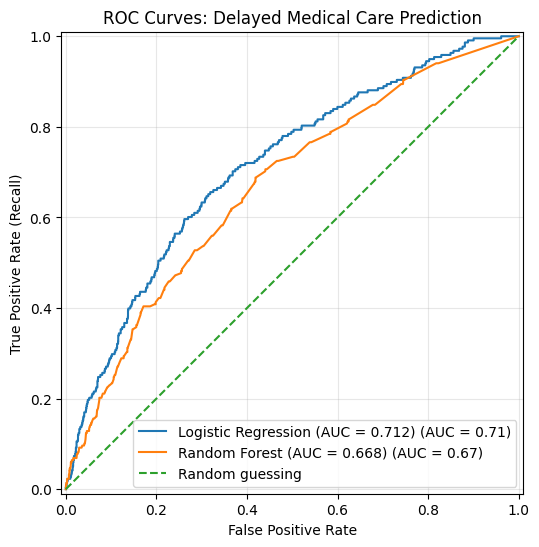

In [47]:

import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, roc_auc_score

# plot ROC curves for both trained models
plt.figure(figsize=(8, 6))

for name, model in models.items():
    # get predicted probabilities for delayed care (class 1)
    y_prob = model.predict_proba(X_test)[:, 1]

    # plot the ROC curve
    RocCurveDisplay.from_predictions(
        y_test,
        y_prob,
        name=f"{name} (AUC = {roc_auc_score(y_test, y_prob):.3f})",
        ax=plt.gca()
    )

# add the reference line for random guessing
plt.plot([0, 1], [0, 1], linestyle="--", label="Random guessing")

plt.title("ROC Curves: Delayed Medical Care Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


#### **Explore Different Classification Threshold**

A classification threshold determines the probability at which a model classifies an observation as positive. Our logistic regression model estimates the probability that an adult delayed medical care due to cost. With the default threshold of 0.50, a predicted probability of at least 0.50 is classified as delayed care; a lower probability is classified as no delay.

Changing the threshold affects the balance between precision and recall:

- **Lower threshold**: More observations are classified as delayed care. This generally increases recall but may also produce more false positives and lower precision.

- **Higher threshold**: Fewer observations are classified as delayed care. This generally reduces false positives and may improve precision, but it can also cause the model to miss more actual delayed-care cases.

The F1-score summarizes the balance between precision and recall, but the best threshold depends on the purpose of the model and the relative importance of false positives and false negatives.

***Interpretation - Classification Threshold Analysis***

To further evaluate logistic regression, we compared classification thresholds of 0.30, 0.40, 0.50, and 0.60. The results showed a trade-off between precision and recall. At a threshold of 0.30, the model achieved the highest recall (90.4%), meaning it identified most adults who delayed medical care due to cost, but precision was only 8.8%. As the threshold increased, precision and F1-score improved while recall decreased. Among the four thresholds tested, 0.60 produced the highest F1-score (0.239) and precision (16.0%), whereas 0.30 produced the highest recall.

These findings demonstrate that the classification threshold affects how the model balances identifying delayed-care cases against generating false positives. The most appropriate threshold depends on the intended use of the model, and further validation would be needed before selecting a final threshold.

***Enhancement 9: Classfication-threshold analysis***

We compared thresholds of 0.30, 0.40, 0.50, and 0.60 to examine how classification decisions affect precision, recall, and F1-score. This is especially useful for our imbalanced outcome, where the default threshold may not provide the most appropriate balance.

*Important limitation*: We used the test set to explore these thresholds, so the comparison should be considered exploratory. Ideally, we would select a threshold using validation data or cross-validation, then evaluate the final model and selected threshold on a separate test set that was not used for model selection.

In [48]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# get logistic regression predicted probabilities
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

# compare several classification thresholds
thresholds = [0.30, 0.40, 0.50, 0.60]

threshold_results = []

for threshold in thresholds:
    # convert probabilities into predicted classes
    y_pred_threshold = (logistic_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(3)


,Threshold,Precision,Recall,F1-score
0,0.3,0.088,0.904,0.161
1,0.4,0.107,0.794,0.189
2,0.5,0.138,0.656,0.227
3,0.6,0.160,0.468,0.239


### **6.8 Feature Importance and Model Interpretation**

After evaluating our models, we examine feature importance to better understand which predictors the random forest relied on most when predicting whether an adult delayed medical care due to cost. While evaluation metrics tell us how well a model performs, feature importance helps us understand which features contributed most to its predictions.

A random forest combines many decision trees. Feature importance in a standard scikit-learn random forest is calculated from how much each feature reduces impurity across the trees, weighted by how often the feature is used. Features with higher importance scores contributed more to reducing impurity within the fitted model. The scores are relative and typically sum to 1 across all features.

Feature importance provides a way to interpret the random forest without examining every individual decision tree. It helps us identify which predictors the model relied on most and compare their relative contributions to its predictions.

**Key steps in our code:**

- `random_forest_model.named_steps["preprocessor"]`: Retrieves the fitted preprocessing component from our pipeline.

- `random_forest_model.named_steps["classifier"]`: Retrieves the trained random forest classifier.

- `get_feature_names_out()`: Retrieves the names of the features after preprocessing, including the new columns created by one-hot encoding.

- `rf_classifier.feature_importances_`: Extracts the random forest's feature importance scores.

- `sort_values(by="Importance", ascending=False)`: Ranks features from most to least important.

- `head(15)`: Selects the 15 highest-ranked features for presentation.

- `plt.barh()`: Creates a horizontal bar chart, making the feature names easier to read.

- `importance_df.head(15).round(4)`: Displays the top 15 features and their importance scores rounded to four decimal places.


***Interpretation***


Feature importance was examined to understand which predictors the random forest model relied on most when predicting delayed medical care due to cost. Age (`AGE23X`) was the most important individual feature, with an importance score of 0.2698, followed by years of education (`EDUCYR`) at 0.1244. Other features among the top 15 included categories of race and ethnicity, marital status, poverty category, sex, perceived physical and mental health, and insurance coverage.

These results suggest that age and education played particularly prominent roles in the model's predictions, while other demographic, socioeconomic, and health-related characteristics also contributed. Because categorical predictors were one-hot encoded, their importance scores represent individual categories rather than the overall importance of each original variable. Feature importance also does not indicate the direction of a relationship or establish causation. Therefore, these findings should be interpreted as indicators of predictive contribution within the random forest model rather than evidence that any characteristic causes delayed medical care.

*Limitations of feature importance* :  Feature importance does not tell us whether a predictor increases or decreases the likelihood of delayed care. It also does not establish causation. Correlated predictors can share or redistribute importance, and impurity-based importance can favor features with more possible split points or categories. Therefore, we interpret these scores as indicators of how the fitted random forest used the available features, not as evidence that a characteristic causes delayed medical care.

***Enhancement 10: Feature-importance visualization***

We extracted and plotted the top 15 random forest feature importance scores. Model performance metrics alone do not show which predictors the model relied on most. This step adds an interpretation step. Age and years of education ranked highest among individual encoded features, while the write-up clarifies that importance does not imply causation or direction of association.

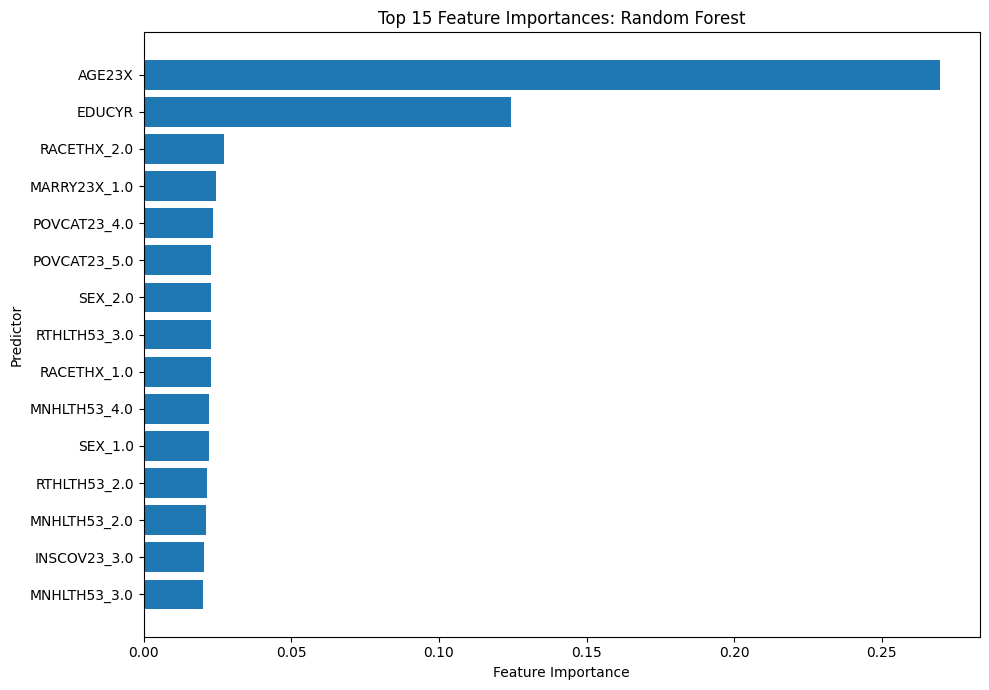

,Feature,Importance
0,AGE23X,0.2698
1,EDUCYR,0.1244
2,RACETHX_2.0,0.0272
3,MARRY23X_1.0,0.0245
4,POVCAT23_4.0,0.0235
5,POVCAT23_5.0,0.0229
6,SEX_2.0,0.0229
7,RTHLTH53_3.0,0.0227
8,RACETHX_1.0,0.0227
9,MNHLTH53_4.0,0.0223


In [49]:

import pandas as pd
import matplotlib.pyplot as plt

# get the fitted preprocessing and random forest components
fitted_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_classifier = random_forest_model.named_steps["classifier"]

# retrieve feature names after preprocessing and encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# extract the random forest feature importance scores
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

# clean up the feature names for readability
importance_df["Feature"] = (
    importance_df["Feature"]
    .str.replace("numeric__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
)

# sort features from most to least important
importance_df = importance_df.sort_values(
    by="Importance", ascending=False
).reset_index(drop=True)

# display the 15 most important features
top_features = importance_df.head(15).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Feature Importance")
plt.ylabel("Predictor")
plt.title("Top 15 Feature Importances: Random Forest")
plt.tight_layout()
plt.show()

# display the ranked feature importance table
importance_df.head(15).round(4)


## **VII. Overall Conclusion and Limitations**

### **Conclusion**

This project examined whether insurance coverage, poverty category, demographic characteristics, and health-related factors could predict whether adults delayed medical care because of cost using the 2023 Medical Expenditure Panel Survey (MEPS). Logistic regression and random forest were trained and evaluated using the same testing dataset.

Overall, logistic regression performed better than random forest at identifying adults who delayed care. Although random forest achieved higher accuracy (91.8%), its recall was only 6.4%, meaning it identified very few respondents who reported delaying care. Logistic regression achieved a recall of 65.6%, an F1-score of 0.227, and a ROC-AUC of 0.712. These results demonstrate why accuracy alone can be misleading when the outcome is imbalanced. The ROC curve also showed that logistic regression had better discriminatory performance than random forest.

The random forest feature importance analysis identified age and years of education as the two most important individual features, followed by several demographic, socioeconomic, and health-related categories. These findings suggest that the selected characteristics contributed differently to the model's predictions. However, feature importance does not establish the direction of a relationship or indicate that a predictor causes delayed care.


### **Limitations**

Several limitations should be considered when interpreting these findings.

1. **Class imbalance** - The target variable was imbalanced, with only 7.25% of adults reporting delayed medical care due to cost. This made it more difficult for the models to identify the minority class reliably. Although class weighting was used during training, neither model performed strongly across all evaluation metrics.

2. **Selected predictors** - The models used a limited set of selected predictors. Other factors that were not included may also be relevant to delayed medical care. In addition, the feature importance results describe predictive contributions rather than causal relationships.

3. **MEPS survey design** - The analysis used standard, unweighted statistical and machine learning methods rather than accounting for the complex survey design of MEPS. The unweighted analysis does not account for the survey weights, strata, and primary sampling units. Therefore, the results should not be interpreted as nationally representative, survey-adjusted estimates. The findings also depend on the selected predictors, preprocessing choices, models, and classification threshold.

4. **Model and threshold limitations** - The classification threshold analysis showed that model performance varied depending on the threshold used. The thresholds explored were evaluated on the test set and should therefore be treated as exploratory rather than as a final threshold-selection procedure. Future work could use cross-validation or a separate validation set to select a threshold, explore additional predictors and modeling approaches, and evaluate performance using methods that account for the MEPS survey design.


Despite these limitations, this project provided practical experience in preparing real-world survey data, handling missing values and categorical predictors, training classification models, and evaluating predictive performance under class imbalance. Overall, logistic regression was the more promising of the two models for identifying adults who delayed medical care due to cost. However, its low precision and the limitations of both models indicate that further improvement and validation would be needed before considering either model for practical use.